# Analysis by events

## Adatok meta leírása (oszloponként)

- **event_id:** Integer	Az esemény egyedi azonosítója. Egy "event" általában egyetlen beeső részecskét (pl. a protont) és az általa keltett összes másodlagos részecskét jelenti.
- **incident_proton_energy:**   Proton energiája

### 📏 Geometriai és Térfogati Mutatók

- **width:**	Szélesség	Az X-tengely menti kiterjedés: xmax​−xmin​
- **height:**	Magasság	Az Y-tengely menti kiterjedés: ymax​−ymin​
- **depth:**	Mélység	A Z-tengely menti kiterjedés: zmax​−zmin​
- **depth_range:**	Mélységi tartomány	A detektált események z-irányú szóródásának hossza.
- **volume	Térfogat:**	A pontfelhőt befoglaló test térfogata.

### ⚡ Statisztikai és Súlypont Adatok

- **num_hits:** A beütések (rekordok) száma a vizsgált csoportban.
- **total_hit_energy:** Az összes beütés összesített energiája (∑Ei​).
- **centroid_x, y, z:** A felhő geometriai középpontja. A koordináták számtani közepe: n1​∑xi​.

### 🌐 Gömbi Koordináta-rendszerű Mérőszámok

- **A számítások alapja a középponttól (vagy origótól) mért távolság: r=x2+y2+z2​.
- **mean_r:**   Átlagos radiális távolság. Megmutatja a felhő átlagos távolságát a viszonyítási ponttól.
- **std_r:**    Radiális szórás. A "felhő vastagsága" – minél nagyobb, annál inkább szétterül a pontfelhő a sugár mentén.
- **max_r:**    A legtávolabbi pont távolsága; a felhő külső határa.
- **weighted_r_mean:**  Energia-súlyozott mélység. Ahol az energia-leadás súlypontja elhelyezkedik a sugár mentén.
- **avg_theta:**    Átlagos polárszög (θ). A függőleges (Z) tengelyhez képesti elhajlás; a "kúp" nyílásszögét jellemzi.
- **avg_phi:**  Átlagos azimutszög (ϕ). Az XY síkban mért elfordulás; az oldalirányú orientációt adja meg.
- **angular_spread:**   Szögirányú szóródás. Azt jelzi, mennyire fókuszált vagy "kúpszerű" a felhő.

### 🧬 Sűrűségi és Intenzitási Mutatók
- **numerical_density:**    Beütéssűrűség, num_hits / volume - Az egységnyi térfogatra jutó események (beütések) száma. Megmutatja, mennyire "sűrű" a pontfelhő; a magas érték szorosan pakolt interakciókat jelez.
- **energy_density:**   Energiasűrűség, total_hit_energy / volume - Az egységnyi térfogatban leadott összes energia. Segít azonosítani a nagy intenzitású "hotspotokat" vagy a kiterjedt, de gyenge energia-leadási zónákat.

In [ ]:
import os
os.chdir('..')

import core

/home/user/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-03-19 08:11:30.036070: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-19 08:11:30.081699: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-19 08:11:31.026380: I tensorflow/core/util/port.cc:153]

In [2]:
df_m1GeV = core.pd.read_csv('../data/szimulaciok/ddsim_vertex0_1GeV_proton_N100000_M1GeV.edm4hep.v2.csv')
df_m2GeV = core.pd.read_csv('../data/szimulaciok/ddsim_vertex0_2GeV_proton_N100000_M2GeV.edm4hep.v2.csv')
df_m5GeV = core.pd.read_csv('../data/szimulaciok/ddsim_vertex0_5GeV_proton_N100000_M5GeV.edm4hep.csv')
df_m10GeV = core.pd.read_csv('../data/szimulaciok/ddsim_vertex0_10GeV_proton_N100000_M10GeV.edm4hep.csv')
df_m20GeV = core.pd.read_csv('../data/szimulaciok/ddsim_vertex0_20GeV_proton_N100000_M20GeV.edm4hep.csv')

len(df_m1GeV), len(df_m2GeV), len(df_m5GeV), len(df_m10GeV), len(df_m20GeV)

(4251035, 11312306, 39832991, 97198362, 212623531)

In [3]:
df_m1GeV.head()

,event_id,hit_index,x,y,z,hit_energy,contribution_time,contribution_energy
0,2,0,1489.072,2147.2,3818.9,1.299598e-05,378.29710,3.063623e-06
1,2,0,1489.072,2147.2,3818.9,1.299598e-05,414.86330,1.670888e-06
2,2,0,1489.072,2147.2,3818.9,1.299598e-05,456.29364,7.334341e-06
3,2,0,1489.072,2147.2,3818.9,1.299598e-05,458.51724,9.271244e-07
4,2,1,1541.746,2094.8,3818.9,3.761918e-08,1269.35910,2.870624e-08


In [4]:
contribution_time_max = 100000
df_m1GeV = df_m1GeV[df_m1GeV['contribution_time'] <= contribution_time_max]
df_m2GeV = df_m2GeV[df_m2GeV['contribution_time'] <= contribution_time_max]
df_m5GeV = df_m5GeV[df_m5GeV['contribution_time'] <= contribution_time_max]
df_m10GeV = df_m10GeV[df_m10GeV['contribution_time'] <= contribution_time_max]
df_m20GeV = df_m20GeV[df_m20GeV['contribution_time'] <= contribution_time_max]

len(df_m1GeV), len(df_m2GeV), len(df_m5GeV), len(df_m10GeV), len(df_m20GeV)

(4250998, 11312264, 39832865, 97198099, 212622958)

In [5]:
shifted_z = 3649
df_m1GeV["z"] = df_m1GeV["z"].apply(lambda z: z-shifted_z)
df_m2GeV["z"] = df_m2GeV["z"].apply(lambda z: z-shifted_z)
df_m5GeV["z"] = df_m5GeV["z"].apply(lambda z: z-shifted_z)
df_m10GeV["z"] = df_m10GeV["z"].apply(lambda z: z-shifted_z)
df_m20GeV["z"] = df_m20GeV["z"].apply(lambda z: z-shifted_z)

In [6]:
df_m1GeV.head()

,event_id,hit_index,x,y,z,hit_energy,contribution_time,contribution_energy
0,2,0,1489.072,2147.2,169.9,1.299598e-05,378.29710,3.063623e-06
1,2,0,1489.072,2147.2,169.9,1.299598e-05,414.86330,1.670888e-06
2,2,0,1489.072,2147.2,169.9,1.299598e-05,456.29364,7.334341e-06
3,2,0,1489.072,2147.2,169.9,1.299598e-05,458.51724,9.271244e-07
4,2,1,1541.746,2094.8,169.9,3.761918e-08,1269.35910,2.870624e-08


In [7]:
df_m1GeV.drop(columns=['hit_index','contribution_time', 'contribution_energy'], inplace=True)
df_m2GeV.drop(columns=['hit_index','contribution_time', 'contribution_energy'], inplace=True)
df_m5GeV.drop(columns=['hit_index','contribution_time', 'contribution_energy'], inplace=True)
df_m10GeV.drop(columns=['hit_index','contribution_time', 'contribution_energy'], inplace=True)
df_m20GeV.drop(columns=['hit_index','contribution_time', 'contribution_energy'], inplace=True)

In [8]:
df_m1GeV.drop_duplicates(inplace=True)
df_m2GeV.drop_duplicates(inplace=True)
df_m5GeV.drop_duplicates(inplace=True)
df_m10GeV.drop_duplicates(inplace=True)
df_m20GeV.drop_duplicates(inplace=True)

In [9]:
df_m1GeV.head()

,event_id,x,y,z,hit_energy
0,2,1489.072,2147.2,169.9,1.299598e-05
4,2,1541.746,2094.8,169.9,3.761918e-08
8,2,1541.746,2046.2,190.4,8.183859e-09
10,2,1541.746,2094.8,190.4,3.724873e-10
11,4,-26.984,478.8,210.9,8.947986e-06


In [10]:
df_m1GeV = core.calc_spherical_coords(df_m1GeV)
print("1GeV gömbi koordináták kiszámolva.")
df_m2GeV = core.calc_spherical_coords(df_m2GeV)
print("2GeV gömbi koordináták kiszámolva.")
df_m5GeV = core.calc_spherical_coords(df_m5GeV)
print("5GeV gömbi koordináták kiszámolva.")
df_m10GeV = core.calc_spherical_coords(df_m10GeV)
print("10GeV gömbi koordináták kiszámolva.")
df_m20GeV = core.calc_spherical_coords(df_m20GeV)
print("20GeV gömbi koordináták kiszámolva.")

df_m1GeV = core.process_event_data(df_m1GeV, '1GeV')
print("1GeV események feldolgozva.")
df_m2GeV = core.process_event_data(df_m2GeV, '2GeV')
print("2GeV események feldolgozva.")
df_m5GeV = core.process_event_data(df_m5GeV, '5GeV')
print("5GeV események feldolgozva.")
df_m10GeV = core.process_event_data(df_m10GeV, '10GeV')
print("10GeV események feldolgozva.")
df_m20GeV = core.process_event_data(df_m20GeV, '20GeV')
print("20GeV események feldolgozva.")

# Első anomália
df_m1GeV.dropna(inplace=True)
df_m2GeV.dropna(inplace=True)
df_m5GeV.dropna(inplace=True)
df_m10GeV.dropna(inplace=True)
df_m20GeV.dropna(inplace=True)

1GeV gömbi koordináták kiszámolva.
2GeV gömbi koordináták kiszámolva.
5GeV gömbi koordináták kiszámolva.
10GeV gömbi koordináták kiszámolva.
20GeV gömbi koordináták kiszámolva.


100%|██████████| 100000/100000 [02:19<00:00, 719.22it/s]


1GeV események feldolgozva.


100%|██████████| 100000/100000 [02:19<00:00, 717.42it/s]


2GeV események feldolgozva.


...

5GeV események feldolgozva.


100%|██████████| 99709/99709 [02:24<00:00, 691.06it/s]


10GeV események feldolgozva.


100%|██████████| 99989/99989 [02:28<00:00, 673.51it/s]


20GeV események feldolgozva.


In [11]:
df_m1GeV.head()

,event_id,incident_proton_energy,width,height,depth,depth_range,volume,num_hits,total_hit_energy,centroid_x,...,centroid_z,mean_r,std_r,max_r,weighted_r_mean,avg_theta,avg_phi,angular_spread,numerical_density,energy_density
0,2,1GeV,52.674,101.0,190.4,20.5,1.012942e+06,4,1.304215e-05,1489.258491,...,169.913449,2600.523321,21.634372,2618.524254,2618.458349,1.501444,0.940544,0.021752,0.000004,1.287552e-11
1,4,1GeV,203.464,101.0,210.9,205.0,4.333966e+06,5,1.530466e-03,-191.466232,...,44.741473,510.239300,38.581328,572.099526,500.879623,1.308170,1.799716,0.449235,0.000001,3.531329e-10
2,17,1GeV,247.329,202.0,190.4,205.0,9.512471e+06,22,1.108440e-03,187.996057,...,54.400032,1003.674834,56.523885,1170.639589,1004.605765,1.502376,-1.409579,0.114486,0.000002,1.165250e-10
3,35,1GeV,48.270,48.6,5.9,20.5,1.384094e+04,5,2.836215e-07,-383.321745,...,-13.440472,869.227769,21.175891,890.620397,869.739014,1.578163,2.071277,0.044079,0.000361,2.049149e-11
4,41,1GeV,48.270,52.4,67.4,82.0,1.704781e+05,7,5.571938e-05,1784.272799,...,59.216366,2314.468929,19.982321,2331.411707,2324.650248,1.555640,-0.703225,0.026077,0.000041,3.268419e-10


## Adatok előkészítése és áttekintése


In [12]:
feature_columns = ["width","height","depth","depth_range","volume","num_hits","total_hit_energy","centroid_x","centroid_y","centroid_z","mean_r","std_r","max_r","weighted_r_mean","avg_theta","avg_phi","angular_spread","numerical_density","energy_density"]
dataframes = {
    "df_m1GeV": df_m1GeV[feature_columns],
    "df_m2GeV": df_m2GeV[feature_columns],
    "df_m5GeV": df_m5GeV[feature_columns],
    "df_m10GeV": df_m10GeV[feature_columns],
    "df_m20GeV": df_m20GeV[feature_columns]
}

In [13]:
dataframes["df_m1GeV"].describe()

,width,height,depth,depth_range,volume,num_hits,total_hit_energy,centroid_x,centroid_y,centroid_z,mean_r,std_r,max_r,weighted_r_mean,avg_theta,avg_phi,angular_spread,numerical_density,energy_density
count,90090.000000,90090.000000,90090.000000,90090.000000,9.009000e+04,90090.000000,9.009000e+04,90090.000000,90090.000000,90090.000000,90090.000000,90090.000000,90090.000000,90090.000000,90090.000000,90090.000000,90090.000000,9.009000e+04,9.009000e+04
mean,331.905686,330.111626,244.285577,215.017216,7.457457e+07,20.700544,1.920797e-03,4.826439,5.228570,123.814705,1514.475582,91.452608,1662.030907,1509.940525,1.459941,0.007616,0.242947,3.132542e+09,3.549410e+06
std,452.479654,449.171594,232.927940,192.886828,3.057597e+08,19.252836,3.337315e-03,1137.284003,1138.899304,162.344602,628.549382,91.505732,637.877854,631.726689,0.145091,1.733838,0.509719,2.899205e+10,6.662374e+07
min,0.000001,0.000001,0.000001,0.000001,5.900000e-12,2.000000,3.722283e-10,-2596.035000,-2599.800000,-14.600000,239.746211,0.000000,245.614393,236.325052,0.212257,-3.131495,0.000126,8.389590e-10,2.333066e-15
25%,100.945000,101.000000,67.400000,82.000000,8.093018e+05,6.000000,1.612057e-04,-820.454425,-818.309202,17.839468,988.619583,39.568814,1126.768012,983.122524,1.425546,-1.475117,0.052405,6.128719e-07,2.634255e-11
50%,206.294000,202.000000,169.900000,164.000000,9.139167e+06,14.000000,6.915872e-04,17.636792,13.261505,67.015041,1428.795365,69.076464,1601.438569,1421.239742,1.510625,0.015209,0.105196,1.761923e-06,8.027665e-11
75%,403.778000,404.000000,333.900000,307.500000,4.777970e+07,29.000000,2.227537e-03,825.012449,832.618268,167.267865,2118.307384,111.938117,2252.502158,2115.523370,1.551503,1.492121,0.191896,8.488823e-06,3.464132e-10
max,5193.922000,5151.000000,1194.900000,1209.500000,1.872970e+10,154.000000,1.012692e-01,2601.035000,2599.800000,1194.898769,2963.807609,1430.308531,3013.794641,2977.208570,1.631471,3.131495,4.455137,3.389831e+11,2.626606e+09


In [14]:
dataframes["df_m2GeV"].describe()

,width,height,depth,depth_range,volume,num_hits,total_hit_energy,centroid_x,centroid_y,centroid_z,mean_r,std_r,max_r,weighted_r_mean,avg_theta,avg_phi,angular_spread,numerical_density,energy_density
count,97021.000000,97021.000000,97021.000000,97021.000000,9.702100e+04,97021.000000,9.702100e+04,97021.000000,97021.000000,97021.000000,97021.000000,97021.000000,97021.000000,97021.000000,97021.000000,97021.000000,97021.000000,9.702100e+04,9.702100e+04
mean,608.891856,607.851076,383.904543,382.763087,2.603464e+08,50.425454,1.112329e-02,3.111224,-1.767186,145.390562,1584.451361,146.618984,1857.805655,1567.929633,1.440391,-0.005694,0.364242,1.492890e+09,2.547472e+06
std,631.828983,631.989614,277.729710,271.917056,6.567241e+08,40.022143,1.218424e-02,1150.673486,1147.938172,148.087100,555.735214,120.392916,577.991837,562.857845,0.130346,1.695463,0.594657,1.971389e+10,5.065664e+07
min,0.000001,0.000001,0.000001,0.000001,5.900000e-12,2.000000,9.981796e-10,-2596.035000,-2599.800000,-14.600000,258.873830,0.000000,287.211982,246.495264,0.333022,-3.131120,0.000219,5.512634e-10,1.630188e-15
25%,254.563000,250.600000,169.900000,164.000000,1.436116e+07,18.000000,1.239626e-03,-880.938812,-884.582261,40.625108,1137.992253,75.505844,1402.666935,1115.516289,1.393371,-1.463071,0.097062,2.817286e-07,2.319586e-11
50%,456.452000,452.600000,333.900000,328.000000,7.462139e+07,41.000000,6.193255e-03,5.752947,-5.708721,104.319297,1576.934306,117.144985,1885.582956,1558.766192,1.479245,-0.007989,0.167600,6.697930e-07,7.944263e-11
75%,708.500000,707.000000,538.900000,533.000000,2.357563e+08,74.000000,1.854276e-02,889.844609,885.490595,206.083816,2064.093842,177.701512,2361.545856,2056.302650,1.530363,1.446212,0.305941,1.708321e-06,3.104958e-10
max,5197.070000,5199.600000,1194.900000,1209.500000,1.517149e+10,307.000000,1.210216e-01,2601.035000,2599.800000,1194.900000,2951.902568,1641.146766,3039.655265,2945.767200,1.612114,3.131495,4.527800,3.389831e+11,2.833686e+09


In [15]:
dataframes["df_m5GeV"].describe()

,width,height,depth,depth_range,volume,num_hits,total_hit_energy,centroid_x,centroid_y,centroid_z,mean_r,std_r,max_r,weighted_r_mean,avg_theta,avg_phi,angular_spread,numerical_density,energy_density
count,96044.000000,96044.000000,96044.000000,96044.000000,9.604400e+04,96044.000000,9.604400e+04,96044.000000,96044.000000,96044.000000,96044.000000,96044.000000,96044.000000,96044.000000,96044.000000,96044.000000,96044.000000,9.604400e+04,9.604400e+04
mean,1286.905630,1290.388866,604.749333,615.211309,1.224049e+09,165.419953,4.052540e-02,5.223472,3.891381,187.035603,1670.960372,237.277170,2185.819958,1649.587754,1.413908,-0.000435,0.591793,2.886009e+08,4.161211e+05
std,941.143910,948.105948,331.793198,332.869220,1.816487e+09,124.661006,4.019846e-02,1168.713484,1173.317137,153.189658,517.411887,144.324032,513.493937,536.853935,0.124781,1.611663,0.685410,8.657950e+09,2.132482e+07
min,0.000001,0.000001,0.000001,0.000001,5.900000e-12,2.000000,4.168366e-10,-2596.035000,-2599.800000,-14.600000,252.304210,0.011243,254.625961,240.014332,0.419073,-3.124214,0.000591,6.377220e-10,3.735654e-16
25%,706.611000,707.000000,333.900000,348.500000,2.698202e+08,59.000000,6.354145e-03,-915.765617,-925.576607,75.940069,1262.347838,147.275684,1826.245919,1223.428705,1.359658,-1.377117,0.191437,9.517322e-08,1.136137e-11
50%,1009.444000,1010.000000,579.900000,594.500000,6.585346e+08,139.000000,2.535659e-02,10.911734,0.733101,149.102497,1697.108950,201.903237,2319.089952,1676.292188,1.444179,0.004914,0.308069,2.698984e-07,4.610687e-11
75%,1559.921000,1563.600000,866.900000,861.000000,1.373879e+09,254.000000,6.972312e-02,924.059409,929.723154,257.988173,2113.126071,285.270903,2614.656110,2111.684211,1.501818,1.381189,0.639451,5.200058e-07,1.201856e-10
max,5197.070000,5199.600000,1194.900000,1209.500000,2.751909e+10,687.000000,2.740126e-01,2601.035000,2599.800000,1191.740331,2861.400334,1540.092616,3060.164884,2951.138523,1.611307,3.120972,4.447340,3.389831e+11,2.494413e+09


In [16]:
dataframes["df_m10GeV"].describe()

,width,height,depth,depth_range,volume,num_hits,total_hit_energy,centroid_x,centroid_y,centroid_z,mean_r,std_r,max_r,weighted_r_mean,avg_theta,avg_phi,angular_spread,numerical_density,energy_density
count,99561.000000,99561.000000,99561.000000,99561.000000,9.956100e+04,99561.000000,9.956100e+04,99561.000000,99561.000000,99561.000000,99561.000000,99561.000000,99561.000000,99561.000000,99561.000000,99561.000000,99561.000000,9.956100e+04,9.956100e+04
mean,1805.564738,1808.708468,785.215277,798.868081,2.765409e+09,361.438545,1.018251e-01,3.013177,1.082521,218.706164,1723.580444,276.828530,2381.058710,1704.794196,1.394393,0.003211,0.684735,4.507913e+07,3.301270e+04
std,1074.100105,1073.353684,315.693794,316.102776,3.093323e+09,233.708079,8.653398e-02,1199.149895,1194.553224,155.322914,491.835805,132.624001,435.754183,518.762632,0.120758,1.582859,0.691407,3.373638e+09,5.401068e+06
min,0.000001,0.000001,0.000001,0.000001,5.900000e-12,2.000000,1.555135e-08,-2588.768954,-2599.800000,-14.600000,267.506938,0.000000,299.570480,269.181713,0.395175,-3.090196,0.001300,1.063437e-09,3.628931e-15
25%,1059.289000,1058.600000,538.900000,553.500000,9.427708e+08,164.000000,2.721038e-02,-965.008298,-962.324621,109.683109,1349.914878,191.206982,2146.305988,1304.897812,1.342772,-1.354007,0.246438,6.150645e-08,1.067464e-11
50%,1415.111000,1414.000000,805.400000,820.000000,1.664209e+09,332.000000,7.516423e-02,3.366394,-0.624666,181.007703,1771.076919,240.756639,2536.589870,1755.296174,1.423366,0.003341,0.390656,2.194325e-07,4.708947e-11
75%,2271.566000,2274.400000,1071.900000,1086.500000,3.252541e+09,538.000000,1.728280e-01,970.059776,964.768382,287.674355,2132.145316,322.679299,2701.192615,2139.651914,1.477619,1.355612,0.807414,4.276013e-07,1.215746e-10
max,5197.070000,5199.600000,1194.900000,1209.500000,3.019908e+10,1245.000000,5.353892e-01,2599.461000,2599.800000,1188.342294,2837.810689,1528.160409,3060.164884,2906.815533,1.591657,3.108941,4.428050,3.389831e+11,1.175066e+09


In [17]:
dataframes["df_m20GeV"].describe()

,width,height,depth,depth_range,volume,num_hits,total_hit_energy,centroid_x,centroid_y,centroid_z,mean_r,std_r,max_r,weighted_r_mean,avg_theta,avg_phi,angular_spread,numerical_density,energy_density
count,99974.000000,99974.000000,99974.000000,99974.000000,9.997400e+04,99974.000000,99974.000000,99974.000000,99974.000000,99974.000000,99974.000000,99974.000000,99974.000000,99974.000000,99974.000000,99974.000000,99974.000000,9.997400e+04,9.997400e+04
mean,2217.829910,2217.215548,940.164698,954.506567,4.884081e+09,710.400094,0.240941,7.777303,0.239821,244.053640,1767.018001,293.788835,2510.708655,1748.962832,1.377146,0.000655,0.704973,4.655442e+06,1.168453e+04
std,1150.111449,1150.656777,266.142078,266.181792,4.521711e+09,390.100975,0.180552,1230.094559,1226.378277,152.618500,478.203807,115.588874,376.875935,509.601785,0.120135,1.580852,0.674881,1.113141e+09,3.042343e+06
min,0.000001,0.000001,0.000001,0.000001,5.900000e-12,2.000000,0.000002,-2583.526569,-2583.975524,-14.600000,446.753431,0.065773,577.075051,459.311379,0.556382,-3.046557,0.006645,1.770821e-09,2.703561e-14
25%,1318.571000,1313.000000,764.400000,779.000000,1.888066e+09,392.000000,0.085435,-997.947083,-998.138314,139.541997,1414.910134,217.689753,2343.185323,1368.549249,1.326426,-1.366908,0.274949,6.216684e-08,1.427554e-11
50%,1772.977000,1769.400000,1030.900000,1045.500000,3.054121e+09,696.000000,0.195439,7.995409,-3.027636,207.695925,1835.727141,261.812211,2643.986811,1819.748580,1.408036,-0.000966,0.427349,2.334678e-07,6.300595e-11
75%,2933.682000,2929.000000,1194.900000,1209.500000,6.370703e+09,1009.000000,0.397249,1014.513108,1003.929673,308.650035,2158.169789,334.863824,2771.976063,2171.970841,1.459283,1.373036,0.826104,4.606466e-07,1.642416e-10
max,5197.070000,5199.600000,1194.900000,1209.500000,3.166220e+10,2045.000000,0.823486,2592.252228,2577.704867,1105.744757,2779.634603,1106.541092,3060.164884,2874.830874,1.578435,3.034048,3.311242,3.389831e+11,9.333423e+08


In [18]:
# @title
# Lists to store the relevant data for concatenation
list_counts_series = []
list_mean_dfs = []
list_std_dfs = []
list_min_dfs = []
list_max_dfs = []
list_quartiles_dfs = []

for name, df in dataframes.items():
    desc = df.describe()

    # For counts, we append the Series directly and set its name
    counts_series = desc.loc['count']
    counts_series.name = name # This will be the index name when DataFrame is created
    list_counts_series.append(counts_series)

    # For mean, std, min, max, quartiles:
    # 1. Select the rows from desc
    # 2. Unstack to get a Series with MultiIndex (column_name, stat_type)
    # 3. Convert to a DataFrame (single column) and transpose to get a single row with MultiIndex columns
    # 4. Set the index of this single-row DataFrame to the original DataFrame name
    # 5. Append to the respective list

    # Mean and Std
    mean_df_part = desc.loc[['mean']].unstack().to_frame().T
    mean_df_part.index = [name]
    list_mean_dfs.append(mean_df_part)

    mean_std_df_part = desc.loc[['std']].unstack().to_frame().T
    mean_std_df_part.index = [name]
    list_std_dfs.append(mean_std_df_part)

    # Min and Max
    min_df_part = desc.loc[['min']].unstack().to_frame().T
    min_df_part.index = [name]
    list_min_dfs.append(min_df_part)

    max_df_part = desc.loc[['max']].unstack().to_frame().T
    max_df_part.index = [name]
    list_max_dfs.append(max_df_part)

    # Quartiles
    quartiles_df_part = desc.loc[['25%', '50%', '75%']].unstack().to_frame().T
    quartiles_df_part.index = [name]
    list_quartiles_dfs.append(quartiles_df_part)

# Combine the lists of single-row DataFrames into final DataFrames
df_counts = core.pd.DataFrame(list_counts_series) # Creates DataFrame with original df names as index

# For mean_std, min_max, quartiles, concatenate and then apply swaplevel and sort_index as per original intent
df_mean = core.pd.concat(list_mean_dfs)
df_mean.columns.names = ['Variable', 'Statistic'] # Name the levels of the MultiIndex
df_mean = df_mean.swaplevel(axis=1).sort_index(axis=1)

df_std = core.pd.concat(list_std_dfs)
df_std.columns.names = ['Variable', 'Statistic'] # Name the levels of the MultiIndex
df_std = df_std.swaplevel(axis=1).sort_index(axis=1)

df_min = core.pd.concat(list_min_dfs)
df_min.columns.names = ['Variable', 'Statistic']
df_min = df_min.swaplevel(axis=1).sort_index(axis=1)

df_max = core.pd.concat(list_max_dfs)
df_max.columns.names = ['Variable', 'Statistic']
df_max = df_max.swaplevel(axis=1).sort_index(axis=1)

df_quartiles = core.pd.concat(list_quartiles_dfs)
df_quartiles.columns.names = ['Variable', 'Statistic']
df_quartiles = df_quartiles.swaplevel(axis=1).sort_index(axis=1)

In [19]:
df_counts

,width,height,depth,depth_range,volume,num_hits,total_hit_energy,centroid_x,centroid_y,centroid_z,mean_r,std_r,max_r,weighted_r_mean,avg_theta,avg_phi,angular_spread,numerical_density,energy_density
df_m1GeV,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0,90090.0
df_m2GeV,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0,97021.0
df_m5GeV,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0,96044.0
df_m10GeV,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0,99561.0
df_m20GeV,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0,99974.0


In [20]:
df_mean

Statistic           mean                                            \
Variable  angular_spread   avg_phi avg_theta centroid_x centroid_y   
df_m1GeV        0.242947  0.007616  1.459941   4.826439   5.228570   
df_m2GeV        0.364242 -0.005694  1.440391   3.111224  -1.767186   
df_m5GeV        0.591793 -0.000435  1.413908   5.223472   3.891381   
df_m10GeV       0.684735  0.003211  1.394393   3.013177   1.082521   
df_m20GeV       0.704973  0.000655  1.377146   7.777303   0.239821   

Statistic                                                                  \
Variable   centroid_z       depth depth_range energy_density       height   
df_m1GeV   123.814705  244.285577  215.017216   3.549410e+06   330.111626   
df_m2GeV   145.390562  383.904543  382.763087   2.547472e+06   607.851076   
df_m5GeV   187.035603  604.749333  615.211309   4.161211e+05  1290.388866   
df_m10GeV  218.706164  785.215277  798.868081   3.301270e+04  1808.708468   
df_m20GeV  244.053640  940.164698  954.506567   1.168453e+04  2217.215548   

Statistic                                                                      \
Variable         max_r       mean_r    num_hits numerical_density       std_r   
df_m1GeV   1662.030907  1514.475582   20.700544      3.132542e+09   91.452608   
df_m2GeV   1857.805655  1584.451361   50.425454      1.492890e+09  146.618984   
df_m5GeV   2185.819958  1670.960372  165.419953      2.886009e+08  237.277170   
df_m10GeV  2381.058710  1723.580444  361.438545      4.507913e+07  276.828530   
df_m20GeV  2510.708655  1767.018001  710.400094      4.655442e+06  293.788835   

Statistic                                                              
Variable  total_hit_energy        volume weighted_r_mean        width  
df_m1GeV          0.001921  7.457457e+07     1509.940525   331.905686  
df_m2GeV          0.011123  2.603464e+08     1567.929633   608.891856  
df_m5GeV          0.040525  1.224049e+09     1649.587754  1286.905630  
df_m10GeV         0.101825  2.765409e+09     1704.794196  1805.564738  
df_m20GeV         0.240941  4.884081e+09     1748.962832  2217.829910

In [21]:
df_std

Statistic            std                                                \
Variable  angular_spread   avg_phi avg_theta   centroid_x   centroid_y   
df_m1GeV        0.509719  1.733838  0.145091  1137.284003  1138.899304   
df_m2GeV        0.594657  1.695463  0.130346  1150.673486  1147.938172   
df_m5GeV        0.685410  1.611663  0.124781  1168.713484  1173.317137   
df_m10GeV       0.691407  1.582859  0.120758  1199.149895  1194.553224   
df_m20GeV       0.674881  1.580852  0.120135  1230.094559  1226.378277   

Statistic                                                                  \
Variable   centroid_z       depth depth_range energy_density       height   
df_m1GeV   162.344602  232.927940  192.886828   6.662374e+07   449.171594   
df_m2GeV   148.087100  277.729710  271.917056   5.065664e+07   631.989614   
df_m5GeV   153.189658  331.793198  332.869220   2.132482e+07   948.105948   
df_m10GeV  155.322914  315.693794  316.102776   5.401068e+06  1073.353684   
df_m20GeV  152.618500  266.142078  266.181792   3.042343e+06  1150.656777   

Statistic                                                                    \
Variable        max_r      mean_r    num_hits numerical_density       std_r   
df_m1GeV   637.877854  628.549382   19.252836      2.899205e+10   91.505732   
df_m2GeV   577.991837  555.735214   40.022143      1.971389e+10  120.392916   
df_m5GeV   513.493937  517.411887  124.661006      8.657950e+09  144.324032   
df_m10GeV  435.754183  491.835805  233.708079      3.373638e+09  132.624001   
df_m20GeV  376.875935  478.203807  390.100975      1.113141e+09  115.588874   

Statistic                                                              
Variable  total_hit_energy        volume weighted_r_mean        width  
df_m1GeV          0.003337  3.057597e+08      631.726689   452.479654  
df_m2GeV          0.012184  6.567241e+08      562.857845   631.828983  
df_m5GeV          0.040198  1.816487e+09      536.853935   941.143910  
df_m10GeV         0.086534  3.093323e+09      518.762632  1074.100105  
df_m20GeV         0.180552  4.521711e+09      509.601785  1150.111449

In [22]:
df_min

Statistic            min                                                \
Variable  angular_spread   avg_phi avg_theta   centroid_x   centroid_y   
df_m1GeV        0.000126 -3.131495  0.212257 -2596.035000 -2599.800000   
df_m2GeV        0.000219 -3.131120  0.333022 -2596.035000 -2599.800000   
df_m5GeV        0.000591 -3.124214  0.419073 -2596.035000 -2599.800000   
df_m10GeV       0.001300 -3.090196  0.395175 -2588.768954 -2599.800000   
df_m20GeV       0.006645 -3.046557  0.556382 -2583.526569 -2583.975524   

Statistic                                                            \
Variable  centroid_z     depth depth_range energy_density    height   
df_m1GeV       -14.6  0.000001    0.000001   2.333066e-15  0.000001   
df_m2GeV       -14.6  0.000001    0.000001   1.630188e-15  0.000001   
df_m5GeV       -14.6  0.000001    0.000001   3.735654e-16  0.000001   
df_m10GeV      -14.6  0.000001    0.000001   3.628931e-15  0.000001   
df_m20GeV      -14.6  0.000001    0.000001   2.703561e-14  0.000001   

Statistic                                                               \
Variable        max_r      mean_r num_hits numerical_density     std_r   
df_m1GeV   245.614393  239.746211      2.0      8.389590e-10  0.000000   
df_m2GeV   287.211982  258.873830      2.0      5.512634e-10  0.000000   
df_m5GeV   254.625961  252.304210      2.0      6.377220e-10  0.011243   
df_m10GeV  299.570480  267.506938      2.0      1.063437e-09  0.000000   
df_m20GeV  577.075051  446.753431      2.0      1.770821e-09  0.065773   

Statistic                                                           
Variable  total_hit_energy        volume weighted_r_mean     width  
df_m1GeV      3.722283e-10  5.900000e-12      236.325052  0.000001  
df_m2GeV      9.981796e-10  5.900000e-12      246.495264  0.000001  
df_m5GeV      4.168366e-10  5.900000e-12      240.014332  0.000001  
df_m10GeV     1.555135e-08  5.900000e-12      269.181713  0.000001  
df_m20GeV     1.591059e-06  5.900000e-12      459.311379  0.000001

In [23]:
df_max

Statistic            max                                                \
Variable  angular_spread   avg_phi avg_theta   centroid_x   centroid_y   
df_m1GeV        4.455137  3.131495  1.631471  2601.035000  2599.800000   
df_m2GeV        4.527800  3.131495  1.612114  2601.035000  2599.800000   
df_m5GeV        4.447340  3.120972  1.611307  2601.035000  2599.800000   
df_m10GeV       4.428050  3.108941  1.591657  2599.461000  2599.800000   
df_m20GeV       3.311242  3.034048  1.578435  2592.252228  2577.704867   

Statistic                                                          \
Variable    centroid_z   depth depth_range energy_density  height   
df_m1GeV   1194.898769  1194.9      1209.5   2.626606e+09  5151.0   
df_m2GeV   1194.900000  1194.9      1209.5   2.833686e+09  5199.6   
df_m5GeV   1191.740331  1194.9      1209.5   2.494413e+09  5199.6   
df_m10GeV  1188.342294  1194.9      1209.5   1.175066e+09  5199.6   
df_m20GeV  1105.744757  1194.9      1209.5   9.333423e+08  5199.6   

Statistic                                                                    \
Variable         max_r       mean_r num_hits numerical_density        std_r   
df_m1GeV   3013.794641  2963.807609    154.0      3.389831e+11  1430.308531   
df_m2GeV   3039.655265  2951.902568    307.0      3.389831e+11  1641.146766   
df_m5GeV   3060.164884  2861.400334    687.0      3.389831e+11  1540.092616   
df_m10GeV  3060.164884  2837.810689   1245.0      3.389831e+11  1528.160409   
df_m20GeV  3060.164884  2779.634603   2045.0      3.389831e+11  1106.541092   

Statistic                                                           
Variable  total_hit_energy        volume weighted_r_mean     width  
df_m1GeV          0.101269  1.872970e+10     2977.208570  5193.922  
df_m2GeV          0.121022  1.517149e+10     2945.767200  5197.070  
df_m5GeV          0.274013  2.751909e+10     2951.138523  5197.070  
df_m10GeV         0.535389  3.019908e+10     2906.815533  5197.070  
df_m20GeV         0.823486  3.166220e+10     2874.830874  5197.070

In [24]:
df_quartiles["25%"]

Variable,angular_spread,avg_phi,avg_theta,centroid_x,centroid_y,centroid_z,depth,depth_range,energy_density,height,max_r,mean_r,num_hits,numerical_density,std_r,total_hit_energy,volume,weighted_r_mean,width
df_m1GeV,0.052405,-1.475117,1.425546,-820.454425,-818.309202,17.839468,67.4,82.0,2.634255e-11,101.0,1126.768012,988.619583,6.0,6.128719e-07,39.568814,0.000161,8.093018e+05,983.122524,100.945
df_m2GeV,0.097062,-1.463071,1.393371,-880.938812,-884.582261,40.625108,169.9,164.0,2.319586e-11,250.6,1402.666935,1137.992253,18.0,2.817286e-07,75.505844,0.001240,1.436116e+07,1115.516289,254.563
df_m5GeV,0.191437,-1.377117,1.359658,-915.765617,-925.576607,75.940069,333.9,348.5,1.136137e-11,707.0,1826.245919,1262.347838,59.0,9.517322e-08,147.275684,0.006354,2.698202e+08,1223.428705,706.611
df_m10GeV,0.246438,-1.354007,1.342772,-965.008298,-962.324621,109.683109,538.9,553.5,1.067464e-11,1058.6,2146.305988,1349.914878,164.0,6.150645e-08,191.206982,0.027210,9.427708e+08,1304.897812,1059.289
df_m20GeV,0.274949,-1.366908,1.326426,-997.947083,-998.138314,139.541997,764.4,779.0,1.427554e-11,1313.0,2343.185323,1414.910134,392.0,6.216684e-08,217.689753,0.085435,1.888066e+09,1368.549249,1318.571


In [25]:
df_quartiles["50%"]

Variable,angular_spread,avg_phi,avg_theta,centroid_x,centroid_y,centroid_z,depth,depth_range,energy_density,height,max_r,mean_r,num_hits,numerical_density,std_r,total_hit_energy,volume,weighted_r_mean,width
df_m1GeV,0.105196,0.015209,1.510625,17.636792,13.261505,67.015041,169.9,164.0,8.027665e-11,202.0,1601.438569,1428.795365,14.0,1.761923e-06,69.076464,0.000692,9.139167e+06,1421.239742,206.294
df_m2GeV,0.167600,-0.007989,1.479245,5.752947,-5.708721,104.319297,333.9,328.0,7.944263e-11,452.6,1885.582956,1576.934306,41.0,6.697930e-07,117.144985,0.006193,7.462139e+07,1558.766192,456.452
df_m5GeV,0.308069,0.004914,1.444179,10.911734,0.733101,149.102497,579.9,594.5,4.610687e-11,1010.0,2319.089952,1697.108950,139.0,2.698984e-07,201.903237,0.025357,6.585346e+08,1676.292188,1009.444
df_m10GeV,0.390656,0.003341,1.423366,3.366394,-0.624666,181.007703,805.4,820.0,4.708947e-11,1414.0,2536.589870,1771.076919,332.0,2.194325e-07,240.756639,0.075164,1.664209e+09,1755.296174,1415.111
df_m20GeV,0.427349,-0.000966,1.408036,7.995409,-3.027636,207.695925,1030.9,1045.5,6.300595e-11,1769.4,2643.986811,1835.727141,696.0,2.334678e-07,261.812211,0.195439,3.054121e+09,1819.748580,1772.977


In [26]:
df_quartiles["75%"]

Variable,angular_spread,avg_phi,avg_theta,centroid_x,centroid_y,centroid_z,depth,depth_range,energy_density,height,max_r,mean_r,num_hits,numerical_density,std_r,total_hit_energy,volume,weighted_r_mean,width
df_m1GeV,0.191896,1.492121,1.551503,825.012449,832.618268,167.267865,333.9,307.5,3.464132e-10,404.0,2252.502158,2118.307384,29.0,8.488823e-06,111.938117,0.002228,4.777970e+07,2115.523370,403.778
df_m2GeV,0.305941,1.446212,1.530363,889.844609,885.490595,206.083816,538.9,533.0,3.104958e-10,707.0,2361.545856,2064.093842,74.0,1.708321e-06,177.701512,0.018543,2.357563e+08,2056.302650,708.500
df_m5GeV,0.639451,1.381189,1.501818,924.059409,929.723154,257.988173,866.9,861.0,1.201856e-10,1563.6,2614.656110,2113.126071,254.0,5.200058e-07,285.270903,0.069723,1.373879e+09,2111.684211,1559.921
df_m10GeV,0.807414,1.355612,1.477619,970.059776,964.768382,287.674355,1071.9,1086.5,1.215746e-10,2274.4,2701.192615,2132.145316,538.0,4.276013e-07,322.679299,0.172828,3.252541e+09,2139.651914,2271.566
df_m20GeV,0.826104,1.373036,1.459283,1014.513108,1003.929673,308.650035,1194.9,1209.5,1.642416e-10,2929.0,2771.976063,2158.169789,1009.0,4.606466e-07,334.863824,0.397249,6.370703e+09,2171.970841,2933.682


## Korelációk elemzése


--- Generating Correlation Matrix for DataFrame: df_m1GeV ---


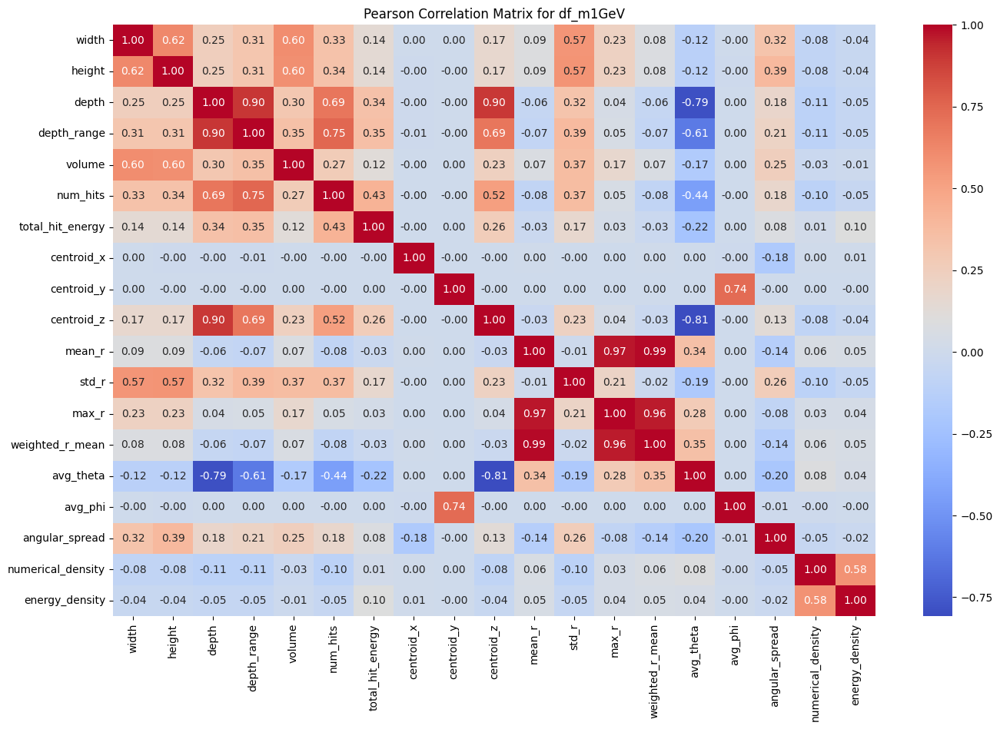


--- Generating Correlation Matrix for DataFrame: df_m2GeV ---


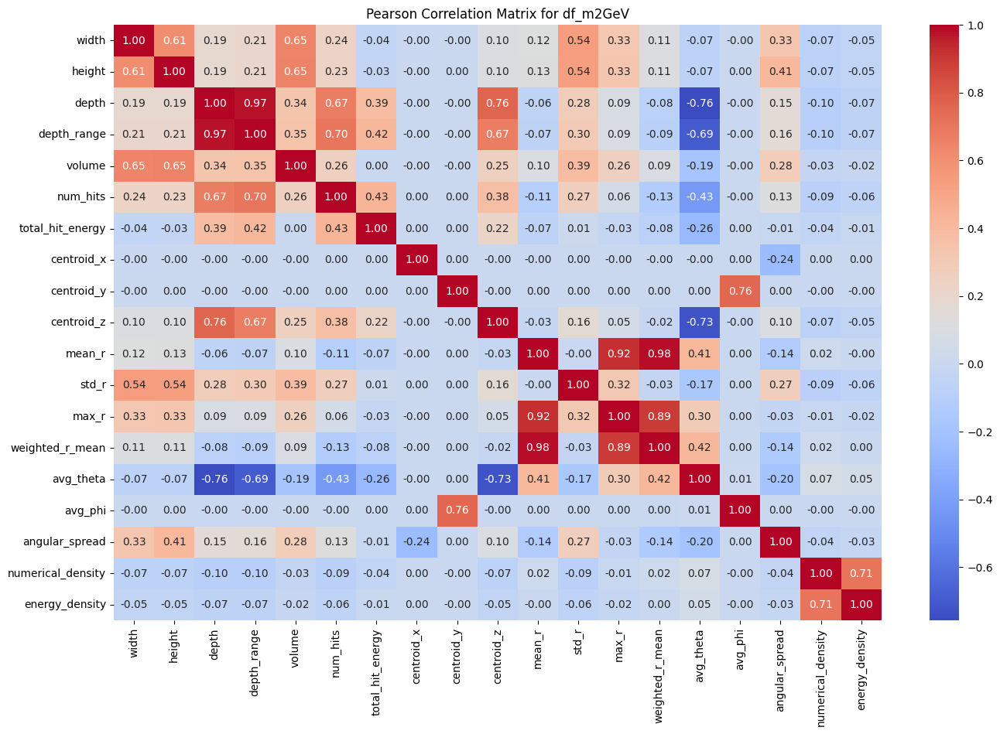


--- Generating Correlation Matrix for DataFrame: df_m5GeV ---


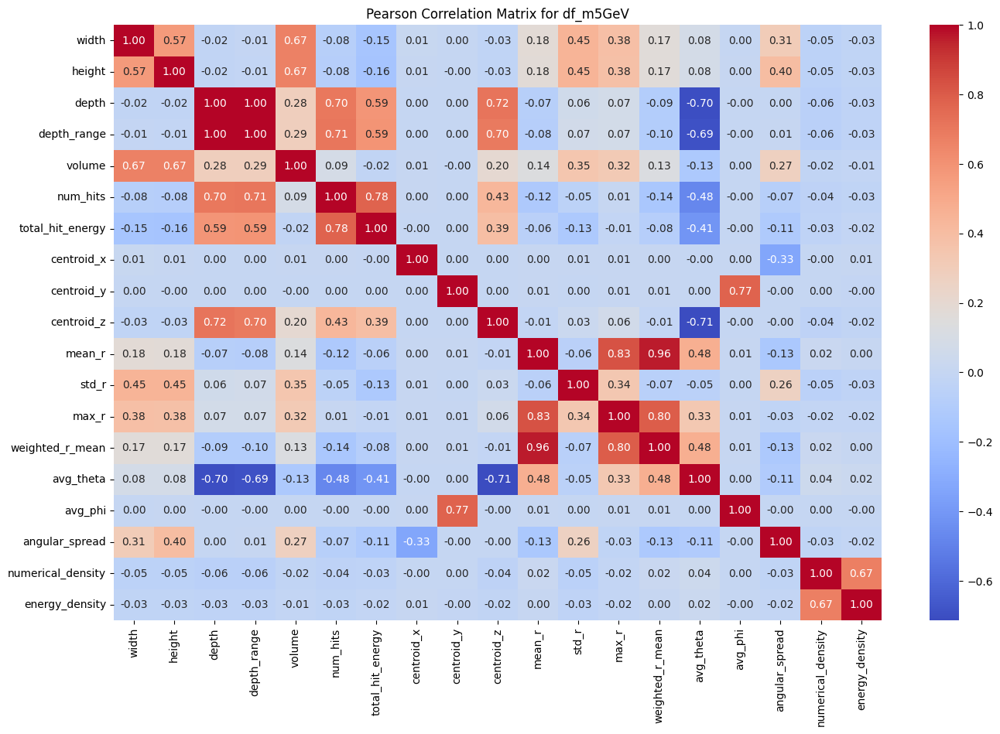


--- Generating Correlation Matrix for DataFrame: df_m10GeV ---


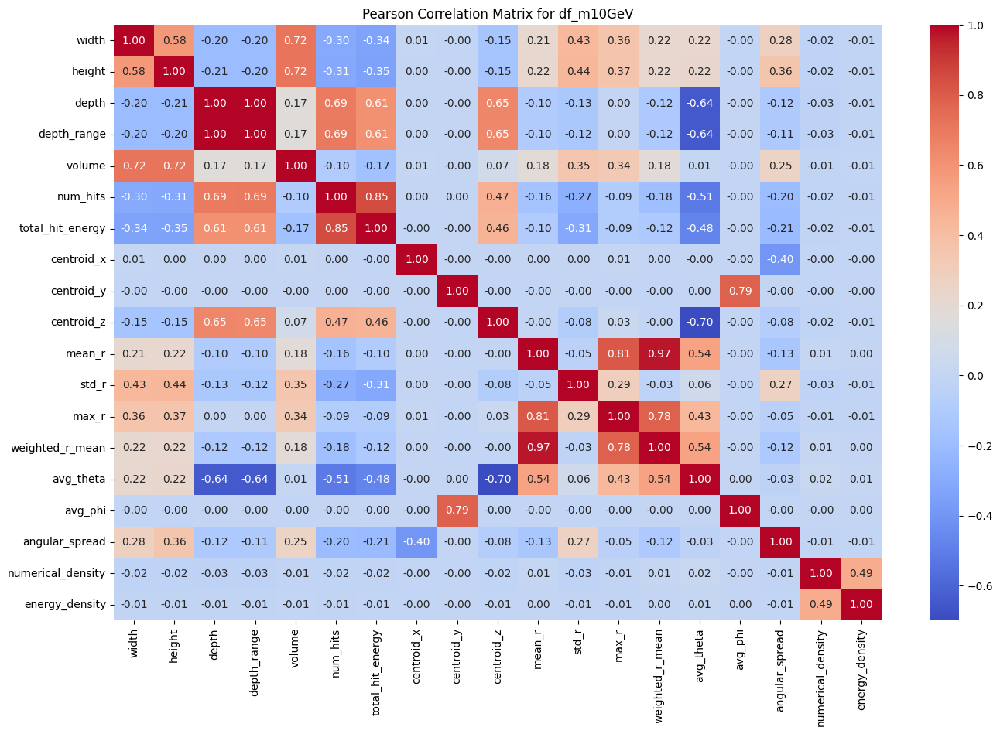


--- Generating Correlation Matrix for DataFrame: df_m20GeV ---


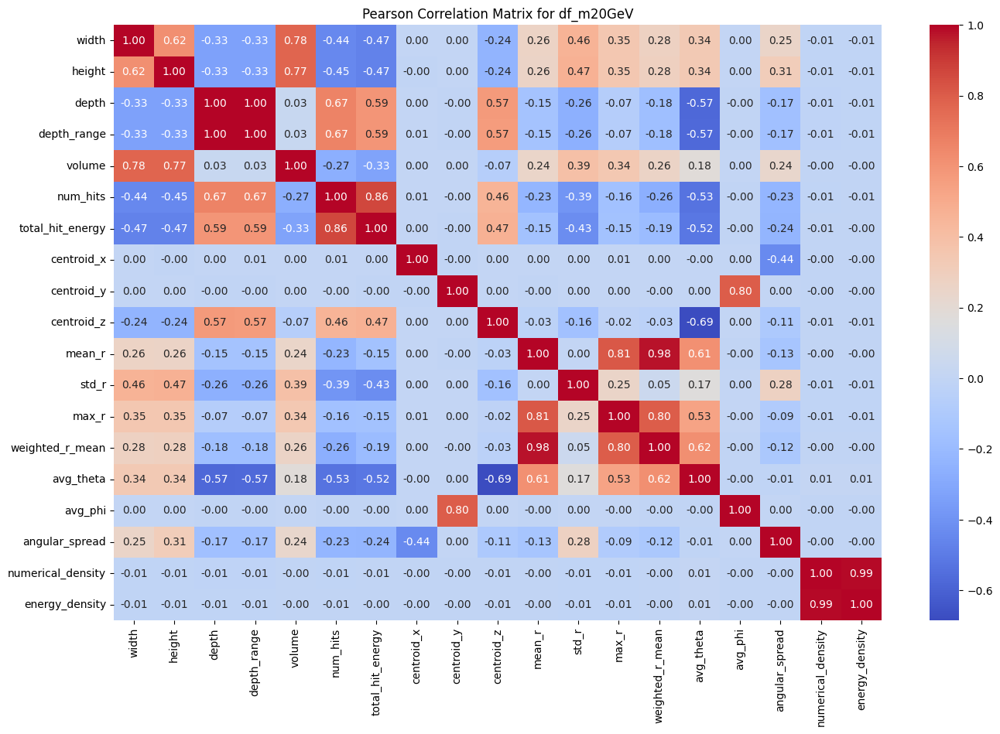

In [27]:
for name, df in dataframes.items():
    print(f"\n--- Generating Correlation Matrix for DataFrame: {name} ---")

    # Calculate the Pearson correlation matrix
    correlation_matrix = df.corr(method='pearson')

    # Visualize the correlation matrix as a heatmap
    core.plt.figure(figsize=(16, 10))
    core.sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
    core.plt.title(f'Pearson Correlation Matrix for {name}')
    core.plt.show()

## Egyedi oszlopok eloszlásának vizsgálata



📊 Gyorsított feldolgozás:   0%|          | 0/19 [00:00<?, ?it/s]

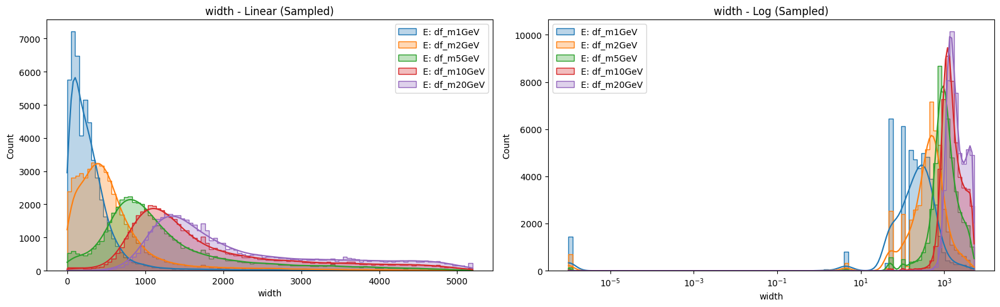

📊 Gyorsított feldolgozás:   5%|▌         | 1/19 [00:01<00:28,  1.61s/it]

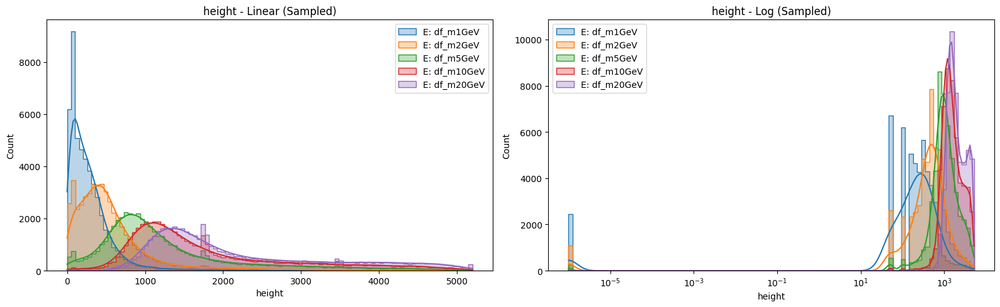

📊 Gyorsított feldolgozás:  11%|█         | 2/19 [00:03<00:31,  1.85s/it]

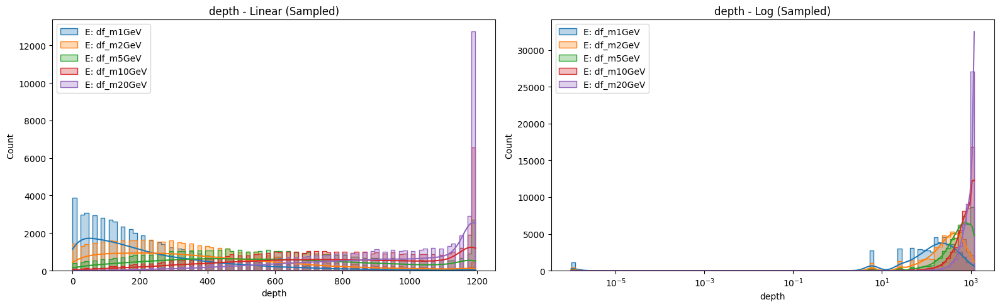

📊 Gyorsított feldolgozás:  16%|█▌        | 3/19 [00:05<00:30,  1.90s/it]

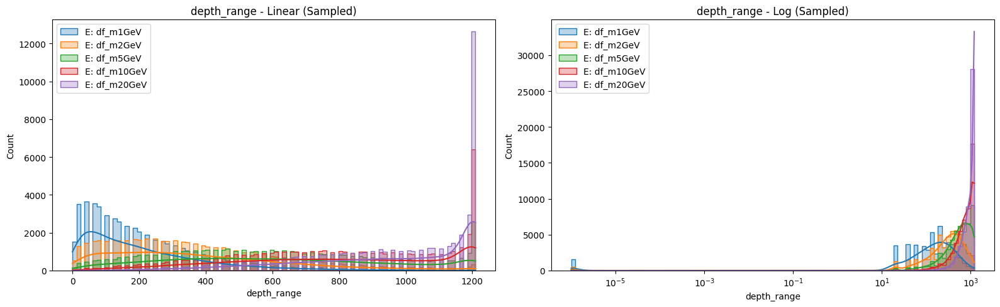

📊 Gyorsított feldolgozás:  21%|██        | 4/19 [00:07<00:26,  1.76s/it]

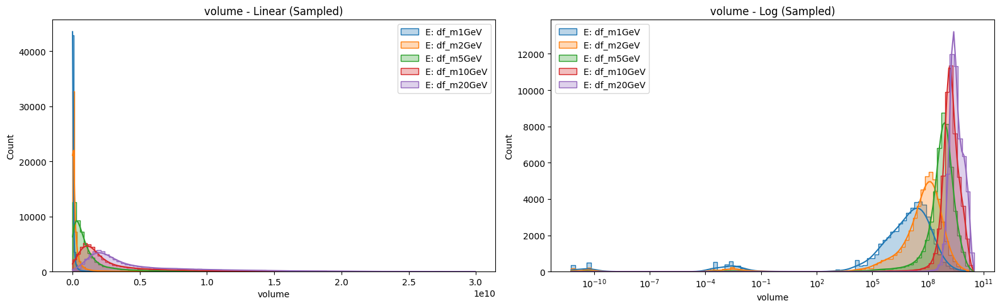

📊 Gyorsított feldolgozás:  26%|██▋       | 5/19 [00:09<00:25,  1.84s/it]

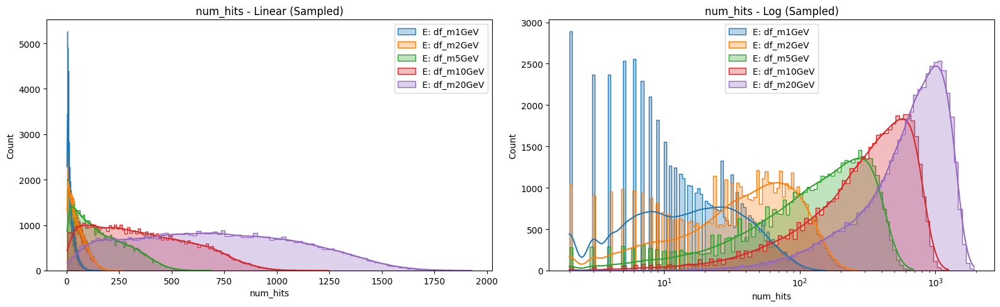

📊 Gyorsított feldolgozás:  32%|███▏      | 6/19 [00:11<00:24,  1.87s/it]

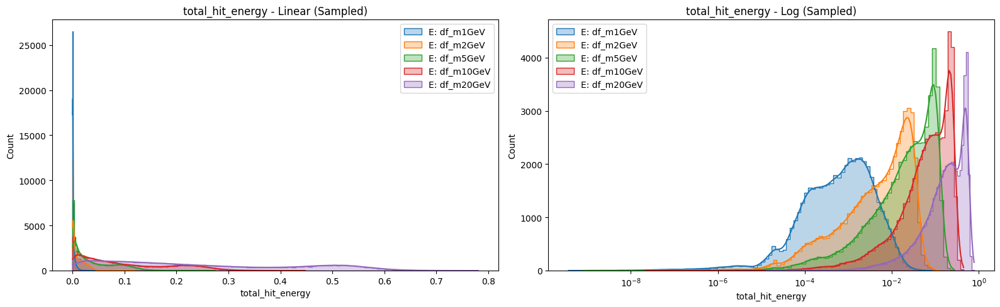

📊 Gyorsított feldolgozás:  37%|███▋      | 7/19 [00:12<00:21,  1.83s/it]

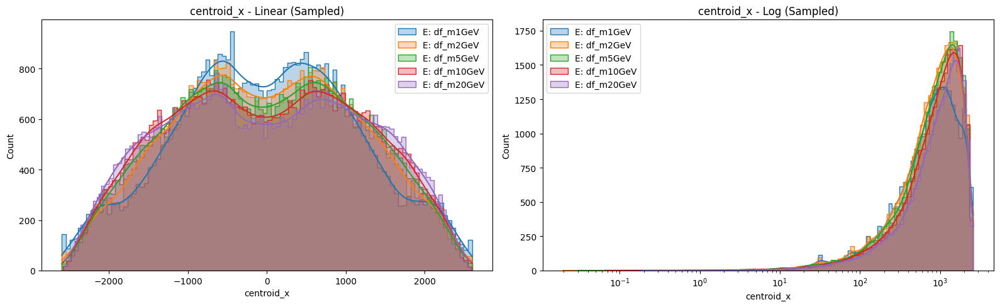

📊 Gyorsított feldolgozás:  42%|████▏     | 8/19 [00:14<00:18,  1.71s/it]

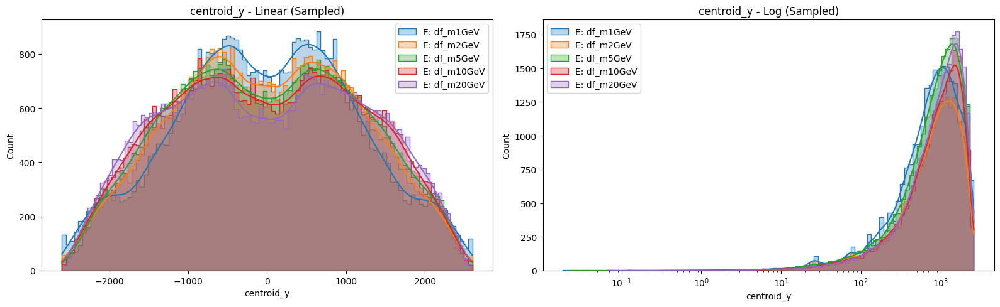

📊 Gyorsított feldolgozás:  47%|████▋     | 9/19 [00:15<00:17,  1.72s/it]

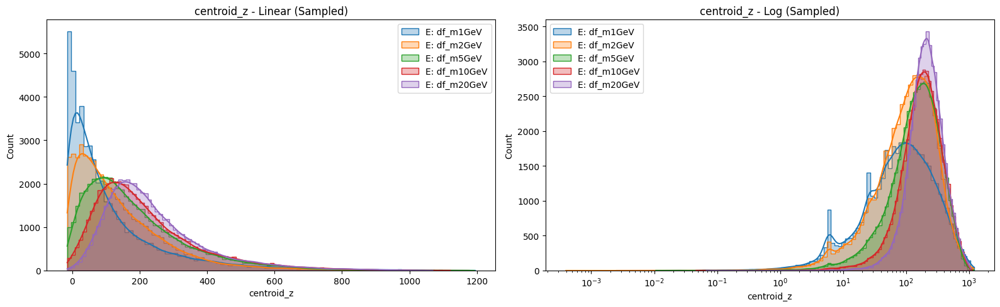

📊 Gyorsított feldolgozás:  53%|█████▎    | 10/19 [00:18<00:16,  1.86s/it]

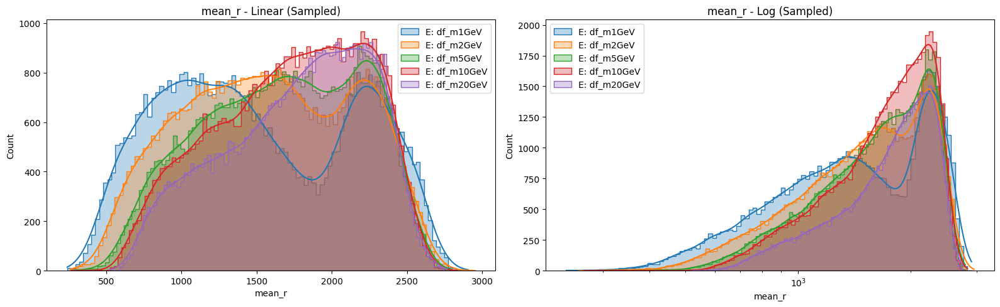

📊 Gyorsított feldolgozás:  58%|█████▊    | 11/19 [00:19<00:14,  1.85s/it]/home/user/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/user/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/user/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


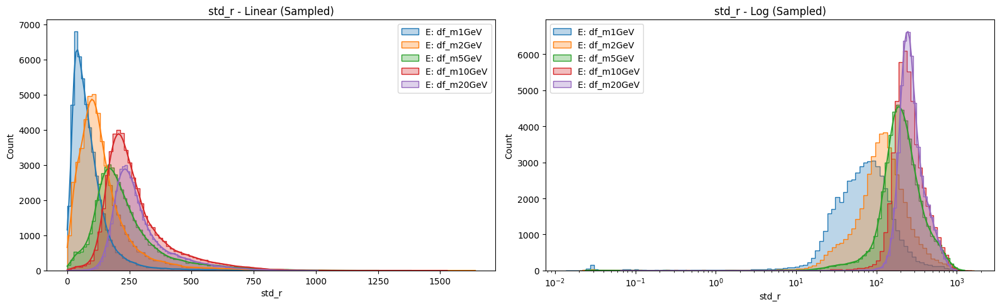

📊 Gyorsított feldolgozás:  63%|██████▎   | 12/19 [00:21<00:12,  1.80s/it]

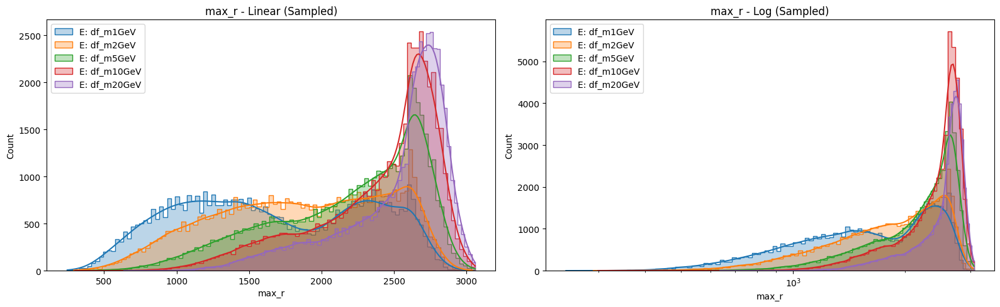

📊 Gyorsított feldolgozás:  68%|██████▊   | 13/19 [00:23<00:11,  1.95s/it]

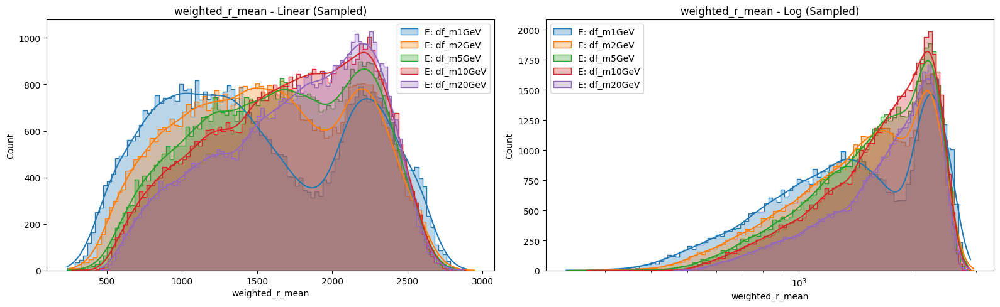

📊 Gyorsított feldolgozás:  74%|███████▎  | 14/19 [00:25<00:09,  1.94s/it]

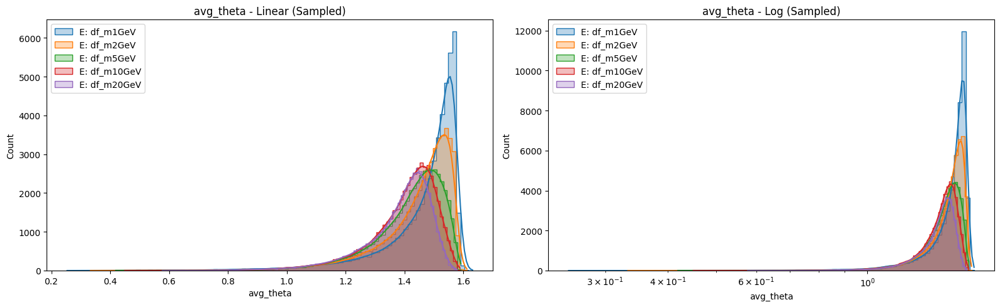

📊 Gyorsított feldolgozás:  79%|███████▉  | 15/19 [00:27<00:07,  1.88s/it]/home/user/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/user/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/user/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


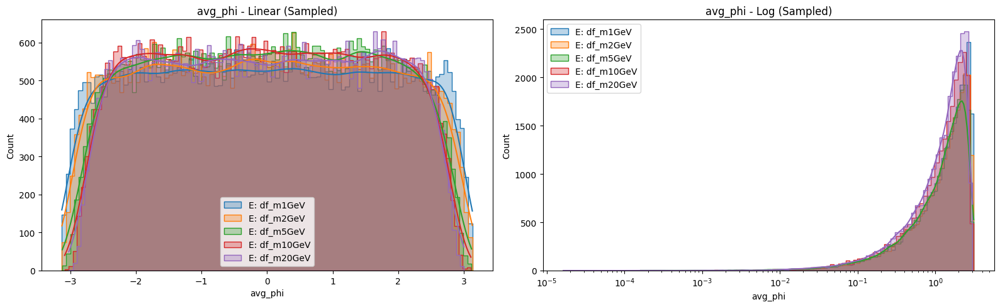

📊 Gyorsított feldolgozás:  84%|████████▍ | 16/19 [00:28<00:05,  1.71s/it]

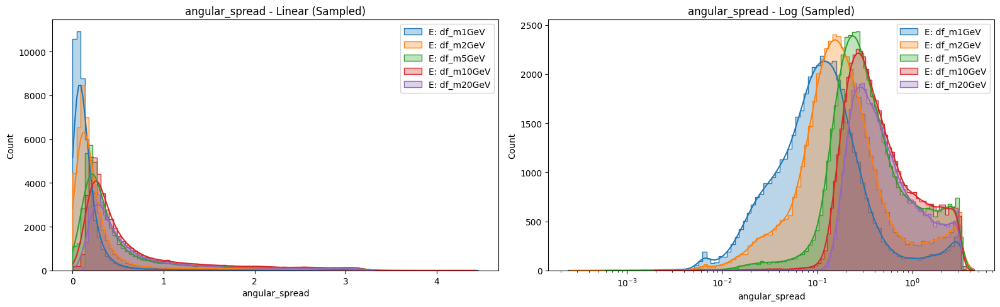

📊 Gyorsított feldolgozás:  89%|████████▉ | 17/19 [00:30<00:03,  1.80s/it]

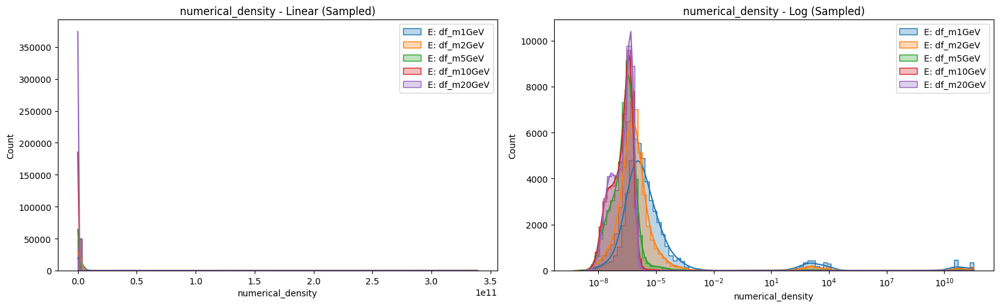

📊 Gyorsított feldolgozás:  95%|█████████▍| 18/19 [00:33<00:01,  1.89s/it]

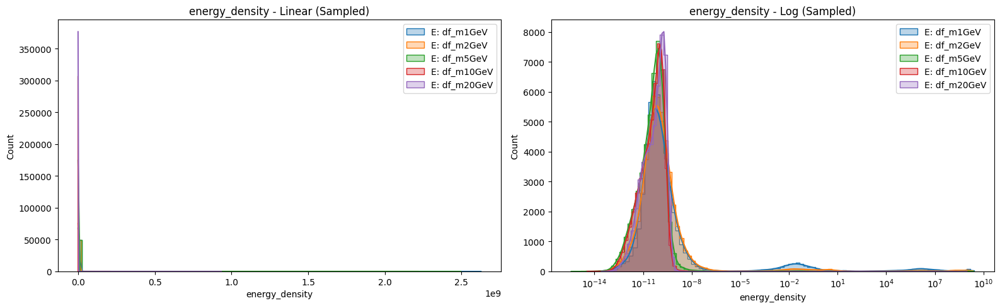

📊 Gyorsított feldolgozás: 100%|██████████| 19/19 [00:35<00:00,  1.85s/it]


In [28]:
for col in core.tqdm(feature_columns, desc="📊 Gyorsított feldolgozás"):
    fig, (ax_lin, ax_log) = core.plt.subplots(1, 2, figsize=(16, 5))
    
    for name, df in dataframes.items():
        data = df[col].dropna() # Üres értékek kiszűrése a biztonság kedvéért
        
        # ELŐ-AGGREGÁCIÓS TRÜKK: 
        # Ha túl sok az adat, csak egy reprezentatív mintát adunk a KDE-nek, 
        # de a hisztogramot a teljes adaton hagyjuk (vagy fordítva).
        # Itt egy 50k-s mintavételt használunk, ami vizuálisan ugyanazt adja.
        sample_size = min(len(data), 50000)
        plot_data = data.sample(sample_size, random_state=42) if len(data) > 50000 else data

        # Lineáris ábrázolás - fix bin számmal (bins=100)
        core.sns.histplot(
            plot_data, 
            kde=True, 
            ax=ax_lin, 
            label=f'E: {name}', 
            element="step", 
            bins=100,      # <--- Fix bin szám = villámgyors számítás
            alpha=0.3
        )
        
        # Logaritmikus ábrázolás
        core.sns.histplot(
            plot_data, 
            kde=True, 
            ax=ax_log, 
            label=f'E: {name}', 
            element="step", 
            log_scale=True, 
            bins=100,      # <--- Log skálán is fixáljuk az oszlopok számát
            alpha=0.3
        )

    ax_lin.set_title(f"{col} - Linear (Sampled)")
    ax_log.set_title(f"{col} - Log (Sampled)")
    ax_lin.legend(); ax_log.legend()
    
    core.plt.tight_layout()
    core.plt.show()
    core.plt.close(fig)

## Energiák és a koordinátákból számított jellemzők közötti kapcsolat vizualizálása

📍 Scatterplotok készítése:   0%|          | 0/19 [00:00<?, ?it/s]

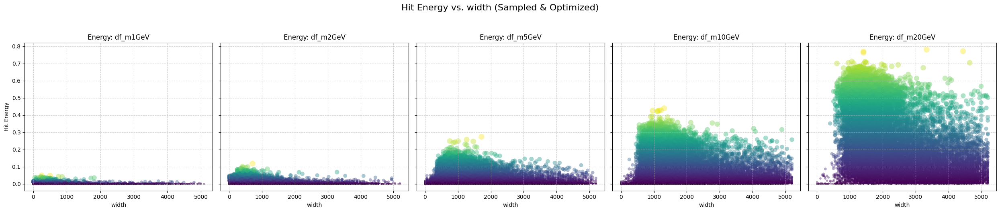

📍 Scatterplotok készítése:   5%|▌         | 1/19 [00:03<01:09,  3.87s/it]

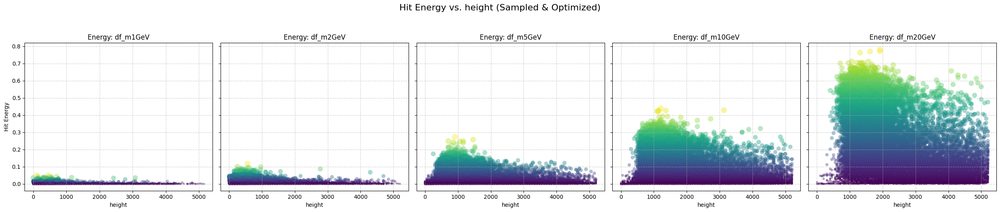

📍 Scatterplotok készítése:  11%|█         | 2/19 [00:07<01:06,  3.94s/it]

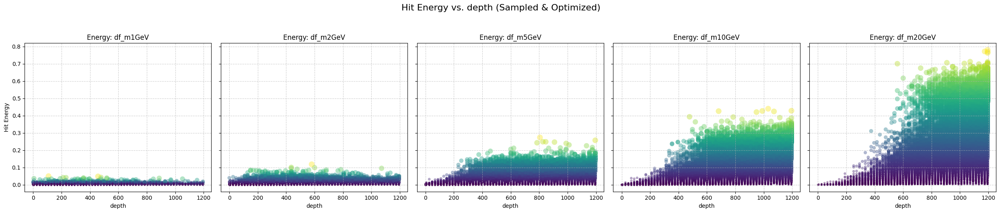

📍 Scatterplotok készítése:  16%|█▌        | 3/19 [00:11<01:02,  3.90s/it]

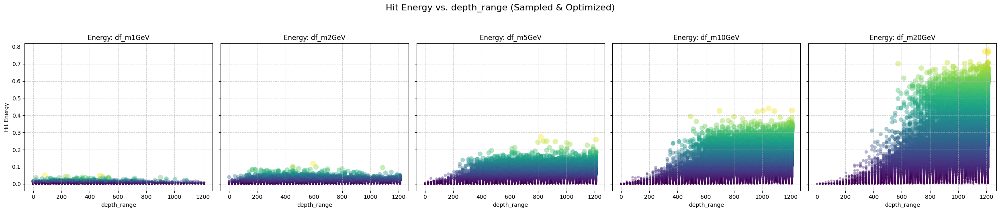

📍 Scatterplotok készítése:  21%|██        | 4/19 [00:15<00:58,  3.93s/it]

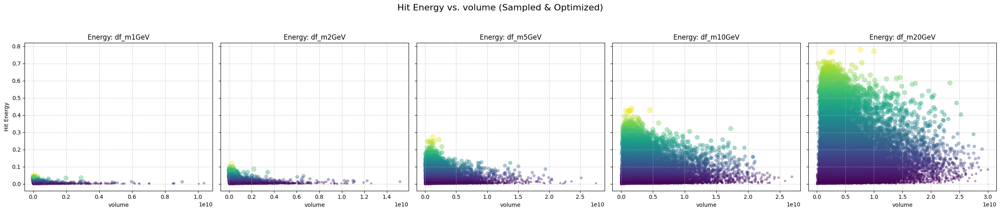

📍 Scatterplotok készítése:  26%|██▋       | 5/19 [00:19<00:54,  3.91s/it]

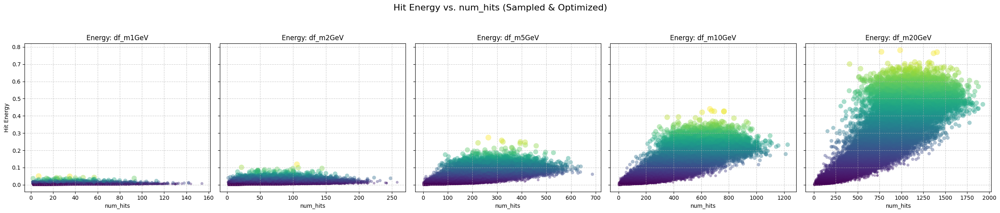

📍 Scatterplotok készítése:  32%|███▏      | 6/19 [00:23<00:51,  3.93s/it]

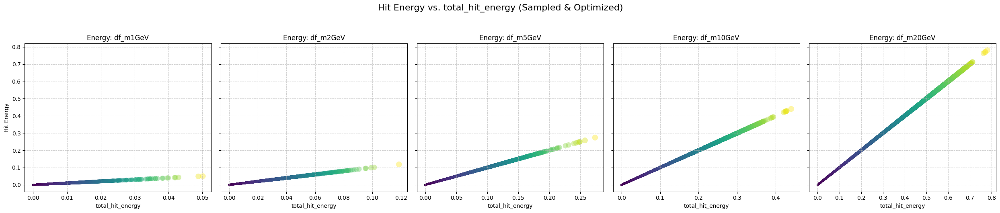

📍 Scatterplotok készítése:  37%|███▋      | 7/19 [00:28<00:49,  4.14s/it]

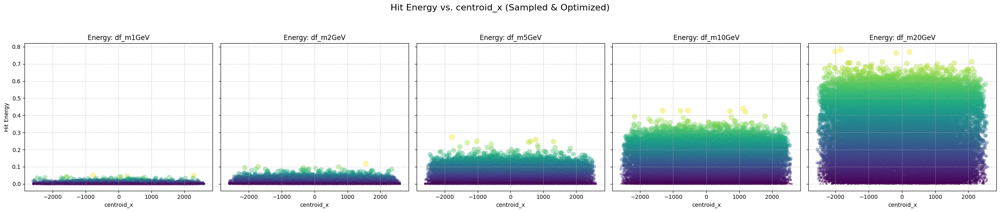

📍 Scatterplotok készítése:  42%|████▏     | 8/19 [00:32<00:44,  4.09s/it]

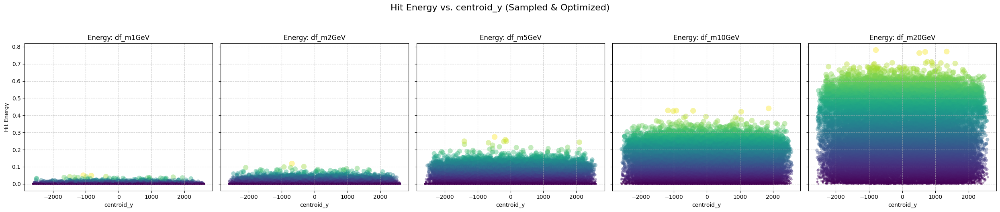

📍 Scatterplotok készítése:  47%|████▋     | 9/19 [00:36<00:40,  4.04s/it]

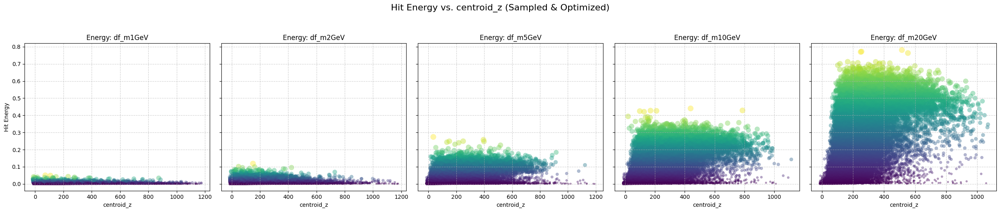

📍 Scatterplotok készítése:  53%|█████▎    | 10/19 [00:39<00:36,  4.01s/it]

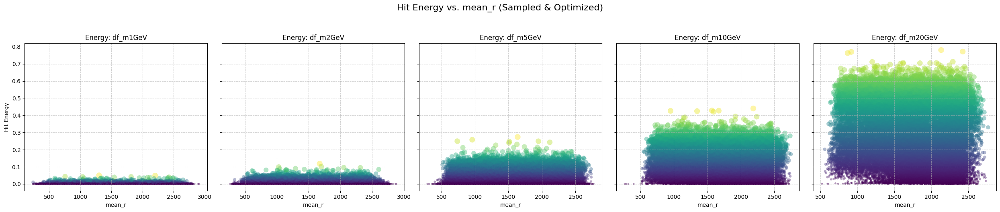

📍 Scatterplotok készítése:  58%|█████▊    | 11/19 [00:43<00:31,  3.97s/it]

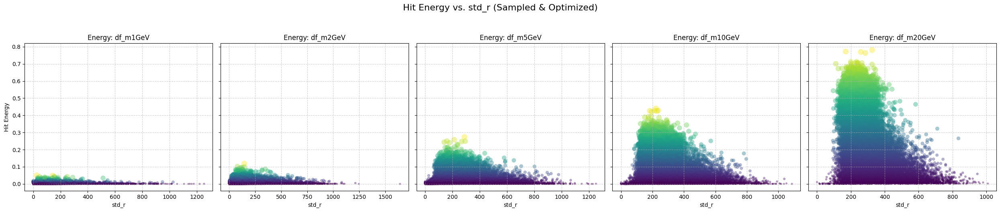

📍 Scatterplotok készítése:  63%|██████▎   | 12/19 [00:47<00:27,  3.96s/it]

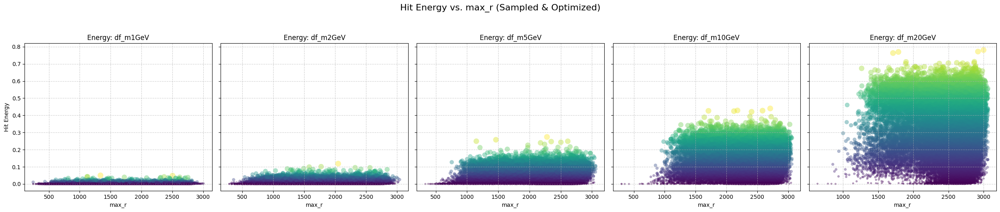

📍 Scatterplotok készítése:  68%|██████▊   | 13/19 [00:51<00:23,  4.00s/it]

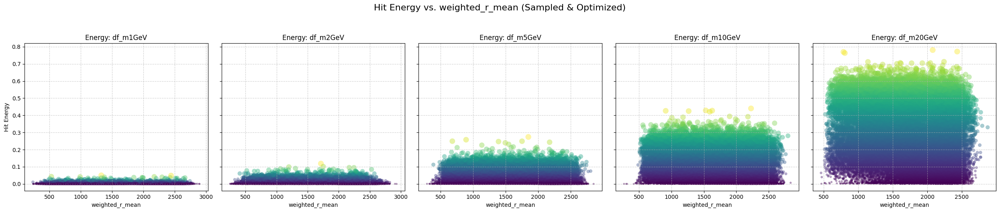

📍 Scatterplotok készítése:  74%|███████▎  | 14/19 [00:55<00:19,  3.95s/it]

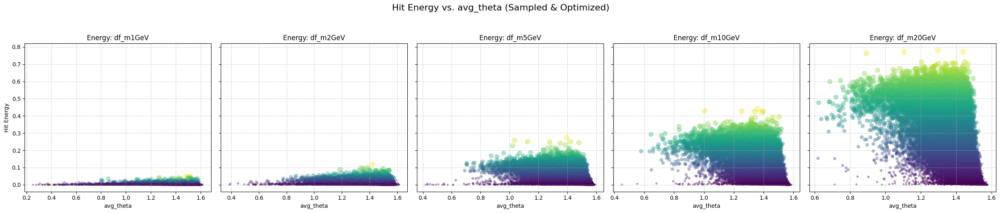

📍 Scatterplotok készítése:  79%|███████▉  | 15/19 [00:59<00:15,  3.97s/it]

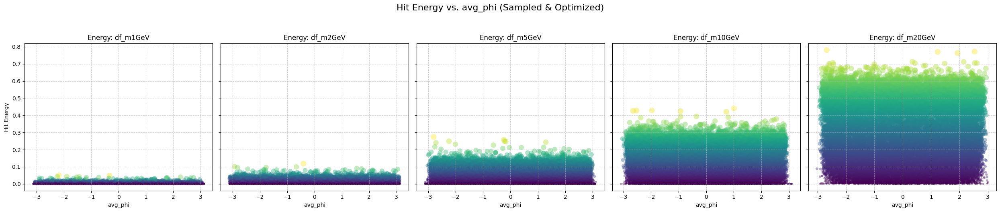

📍 Scatterplotok készítése:  84%|████████▍ | 16/19 [01:03<00:11,  3.94s/it]

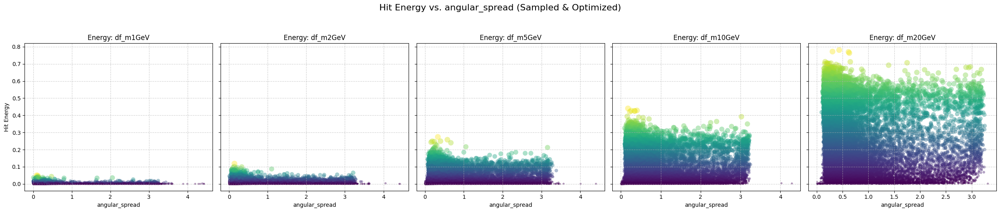

📍 Scatterplotok készítése:  89%|████████▉ | 17/19 [01:07<00:07,  3.96s/it]

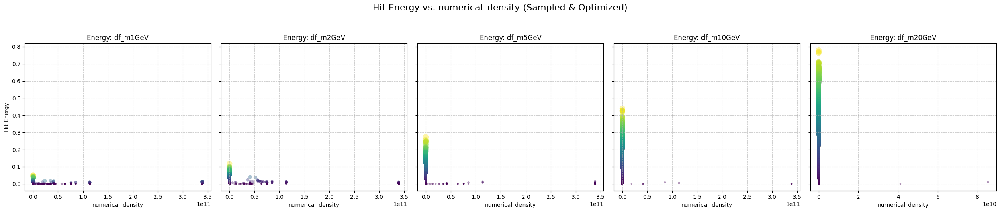

📍 Scatterplotok készítése:  95%|█████████▍| 18/19 [01:11<00:03,  3.90s/it]

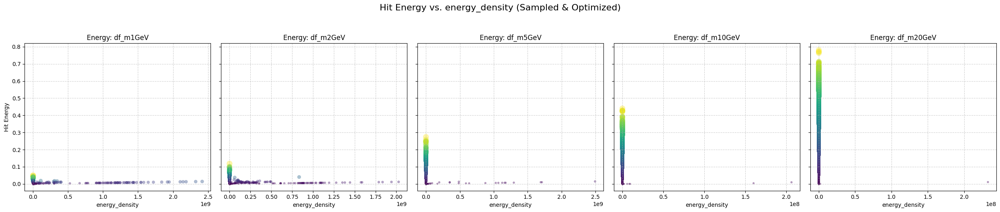

📍 Scatterplotok készítése: 100%|██████████| 19/19 [01:16<00:00,  4.01s/it]


In [29]:
num_energies = len(dataframes)

# Itt is a jellemzőkön megyünk végig
for col in core.tqdm(feature_columns, desc="📍 Scatterplotok készítése"):
    
    fig, axes = core.plt.subplots(1, num_energies, figsize=(5 * num_energies, 5), sharey=True)

    if num_energies == 1:
        axes = [axes]

    for i, (name, df) in enumerate(dataframes.items()):
        # --- GYORSÍTÁSI STRATÉGIA: MINTAVÉTELEZÉS ---
        # 20-30 ezer pont bőven elég a trendek és sűrűségek láttatásához
        if len(df) > 30000:
            df_plot = df.sample(30000, random_state=42)
        else:
            df_plot = df

        core.sns.scatterplot(
            x=col,
            y='total_hit_energy',  # Y tengelyen a teljes hit energia, hogy lássuk az összefüggést
            hue='total_hit_energy',
            size='total_hit_energy',
            data=df_plot,
            palette='viridis',
            sizes=(10, 100), # Kicsit kisebb pontok a jobb átláthatóságért
            ax=axes[i],
            legend=False,
            alpha=0.4,       # Átlátszóság: segít látni a sűrűbb pontfelhőket
            edgecolor=None,  # Körvonal kikapcsolása (rengeteg időt spórol a renderelésnél)
            rasterized=True  # TRÜKK: a pontokat pixelgrafikusan rajzolja, a tengelyeket vektorgrafikusan
        )

        axes[i].set_title(f'Energy: {name}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Hit Energy' if i == 0 else "")
        axes[i].grid(True, linestyle='--', alpha=0.6)

    fig.suptitle(f'Hit Energy vs. {col} (Sampled & Optimized)', fontsize=16, y=1.05)
    core.plt.tight_layout()
    core.plt.show()
    
    # Memória felszabadítása
    core.plt.close(fig)

In [30]:
all_energy_df = core.pd.concat([df_m1GeV, df_m2GeV, df_m5GeV, df_m10GeV, df_m20GeV], ignore_index=True)

In [31]:
all_energy_df.to_csv('../data/processed/all_energy_df_v4.csv', index=False)

In [32]:
# Elemezd ki az mérési eredményeket a következő kérdések alapján: 
# - Milyen mintázatok figyelhetők meg a különböző energiaszinetek esetében és az mire utalhat?
# - Milyen lehetőségeket látsz az anomáliák meghatározására.
# - Melyek a legfontosabb jellemzők ha meg szeretnék prediktálni a különböző energiaszinteket (1GeV, 2Gev, 5Gev, 10Gev, 20Gev) az események alapján?
# - Milyen egyéb megfigyeléseket veszel észre a mérési eredmények alapján?